# Tomato Leaf Disease Classifier: CNN Base Model
**ICS 3202 Semester Project, Deliverable 2 (ML Engine)**
Team: Mohamed Abdi, Elvis Mwangi, Mark Kiplangat

**Problem:** A smallholder farmer photographs a tomato leaf and the app says which disease it has, or that the leaf is healthy.
**ML task:** Supervised multi-class image classification (10 classes).
**Dataset:** PlantVillage, tomato subset.
**Base model:** Convolutional Neural Network (CNN).

**Contents**
1. Setup and data loading
2. Data cleaning and EDA (Question 2)
3. Modelling and validation of the base model (Question 3)
4. Further validation plan (Question 4)

## 1. Setup and data loading

**Idea first:** A CNN works like a person learning to spot a disease. Early layers notice simple things (edges, colour changes), later layers combine them into patterns (a ring-shaped spot, a yellow curl), and the final layer decides which disease those patterns best match.

In [7]:
import random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers

# Fix random seeds so results can be reproduced
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Folder that CONTAINS the class folders (e.g. Tomato___Late_blight, ...)
DATA_DIR = Path("PlantVillage")
IMG_SIZE = (128, 128)   # smaller than 256 to train faster; also suits a mobile app
BATCH = 32

In [16]:
# Build a table of every image path and its label (the folder name)
rows = []
for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir() and "tomato" in class_dir.name.lower():
        for f in class_dir.iterdir():
            if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                rows.append({"path": str(f), "label": class_dir.name})

df = pd.DataFrame(rows)
print("Total images found:", len(df))
print("Number of classes:", df.label.nunique())
df.label.value_counts()

Total images found: 16011
Number of classes: 10


,count
label,
Tomato__Tomato_YellowLeaf__Curl_Virus,3208
Tomato_Bacterial_spot,2127
Tomato_Late_blight,1909
Tomato_Septoria_leaf_spot,1771
Tomato_Spider_mites_Two_spotted_spider_mite,1676
Tomato_healthy,1591
Tomato__Target_Spot,1404
Tomato_Early_blight,1000
Tomato_Leaf_Mold,952


In [17]:
from pathlib import Path

print("Files in /content:", [x.name for x in Path("/content").iterdir()])

found = None
for p in Path("/content").rglob("*"):
    if p.is_dir() and "tomato" in p.name.lower():
        found = p.parent
        break

if found:
    DATA_DIR = found
    print("DATA_DIR set to:", DATA_DIR)
else:
    print("No tomato folders found")

Files in /content: ['.config', 'plant-village.zip', 'pv', 'sample_data']
DATA_DIR set to: /content/pv/PlantVillage


In [15]:
import os
os.environ["KAGGLE_API_TOKEN"] = ""

!pip install -q --upgrade kaggle
!kaggle datasets download -d arjuntejaswi/plant-village -p /content
!unzip -q /content/plant-village.zip -d /content/pv

from pathlib import Path
found = None
for p in Path("/content").rglob("*"):
    if p.is_dir() and "tomato" in p.name.lower():
        found = p.parent
        break

if found:
    DATA_DIR = found
    print("DATA_DIR set to:", DATA_DIR)
else:
    print("No tomato folders found")

Dataset URL: https://www.kaggle.com/datasets/arjuntejaswi/plant-village
License(s): unknown
100% 329M/329M [00:08<00:00, 39.4MB/s]

DATA_DIR set to: /content/pv/PlantVillage


In [18]:
from pathlib import Path

found = None
for p in Path("/content").rglob("*"):
    if p.is_dir() and "tomato" in p.name.lower():
        found = p.parent
        break

if found:
    DATA_DIR = found
    print("DATA_DIR set to:", DATA_DIR)
else:
    print("No tomato folders found. Files in /content:")
    print([x.name for x in Path("/content").iterdir()])

DATA_DIR set to: /content/pv/PlantVillage


In [19]:
!ls /content

plant-village.zip  pv  sample_data


In [20]:
from pathlib import Path

found = None
for p in Path("/content").rglob("*"):
    if p.is_dir() and "tomato" in p.name.lower():
        found = p.parent
        break

if found:
    DATA_DIR = found
    print("DATA_DIR set to:", DATA_DIR)
    print("Folders inside:", [d.name for d in DATA_DIR.iterdir()][:12])
else:
    print("No tomato folders found. What is in /content:")
    print([x.name for x in Path("/content").iterdir()])

DATA_DIR set to: /content/pv/PlantVillage
Folders inside: ['Tomato_Leaf_Mold', 'Tomato__Tomato_mosaic_virus', 'Tomato__Target_Spot', 'Potato___Early_blight', 'Pepper__bell___healthy', 'Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_healthy', 'Potato___Late_blight']


In [ ]:
!ls /content
!ls /content/pv

In [ ]:
from pathlib import Path
for p in Path("/content").rglob("*"):
    if p.is_dir() and "tomato" in p.name.lower():
        print(p.parent)
        break

## 2. Data cleaning and EDA (Question 2)

**Idea first:** A model only learns from what it is shown, so mistakes in the data become mistakes in the model. Before modelling we check the data for broken files, duplicates, inconsistent sizes and unbalanced classes.

### 2.1 Exploration

In [21]:
import os
os.environ["KAGGLE_API_TOKEN"] = ""

In [22]:
!pip install -q --upgrade kaggle
!kaggle datasets download -d arjuntejaswi/plant-village -p /content
!unzip -q /content/plant-village.zip -d /content/pv
!ls /content/pv


Dataset URL: https://www.kaggle.com/datasets/arjuntejaswi/plant-village
License(s): unknown
plant-village.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/pv/PlantVillage/Pepper__bell___Bacterial_spot/0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG? [y]es, [n]o, [A]ll, [N]one, [r]ename: PlantVillage


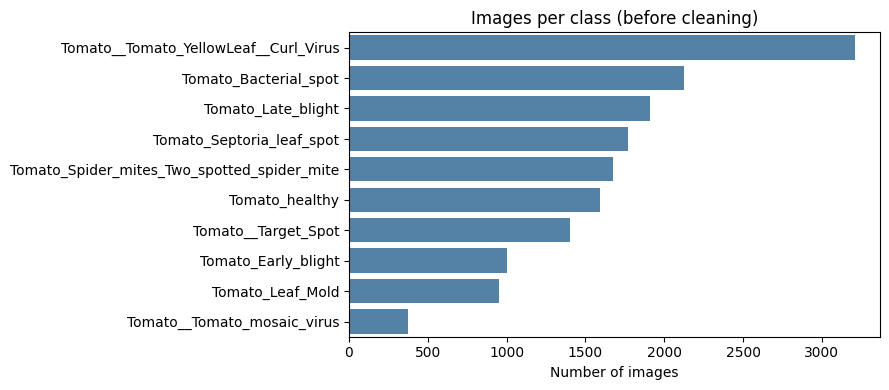

Imbalance ratio (largest / smallest class): 8.6


In [23]:
# Class distribution
counts = df.label.value_counts()
plt.figure(figsize=(9, 4))
sns.barplot(x=counts.values, y=[l.replace("Tomato___", "") for l in counts.index], color="steelblue")
plt.xlabel("Number of images"); plt.title("Images per class (before cleaning)")
plt.tight_layout(); plt.show()

print("Imbalance ratio (largest / smallest class):", round(counts.max() / counts.min(), 1))

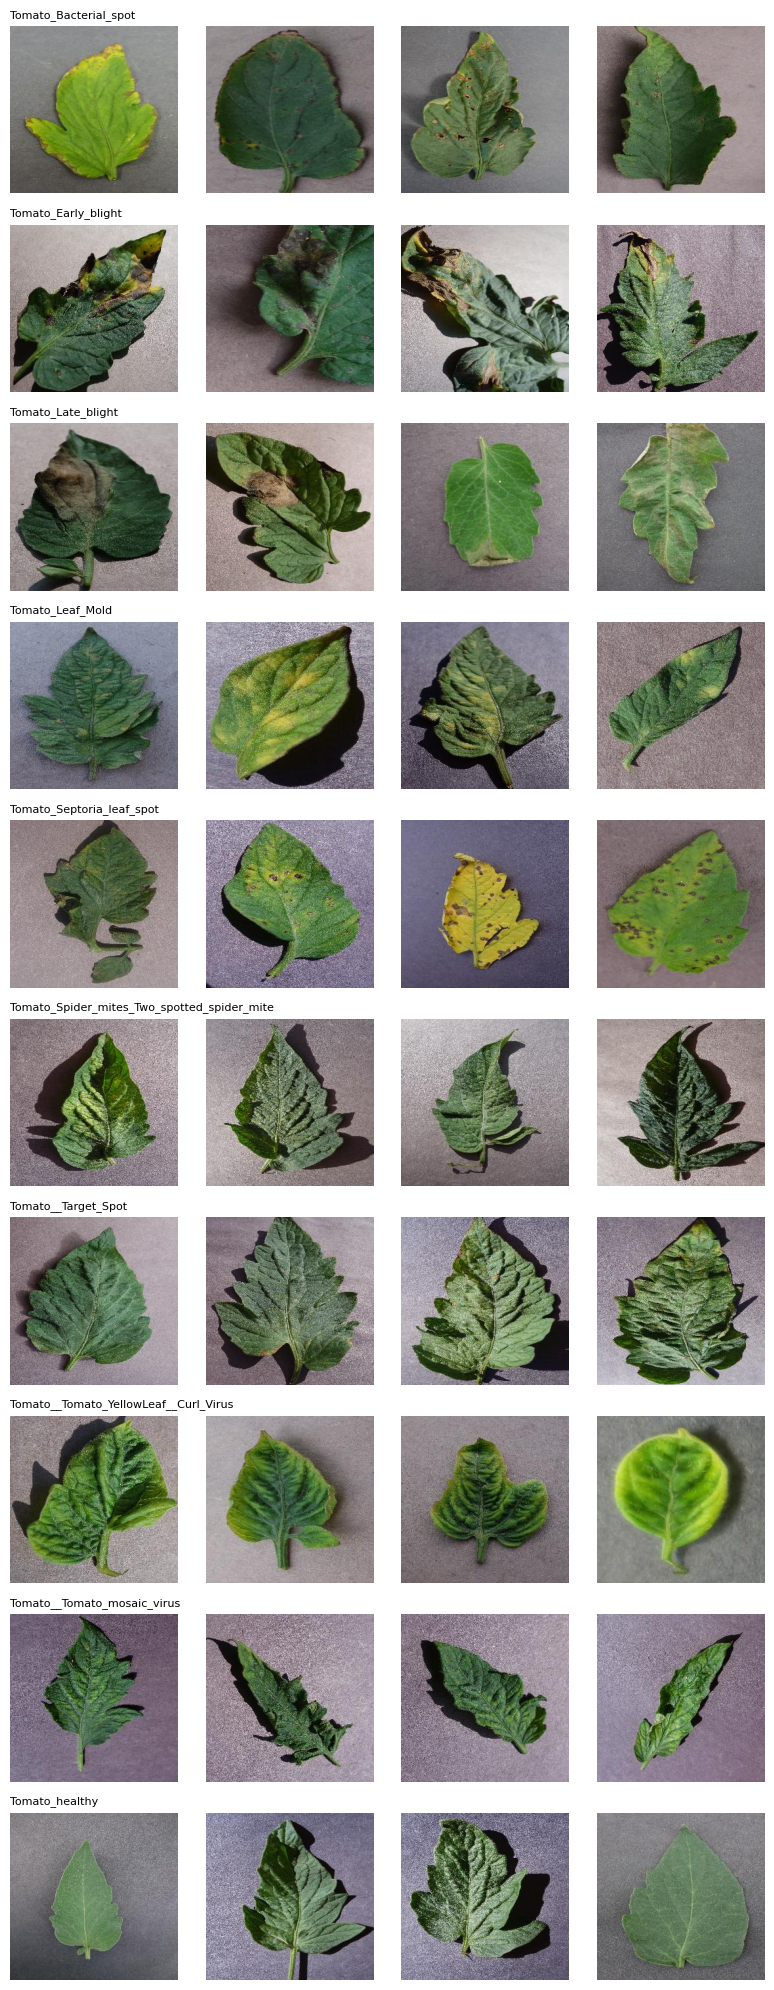

In [24]:
# Look at a few samples from each class
classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(8, 2 * len(classes)))
for i, c in enumerate(classes):
    samples = df[df.label == c].sample(4, random_state=SEED).path
    for j, p in enumerate(samples):
        axes[i, j].imshow(Image.open(p)); axes[i, j].axis("off")
    axes[i, 0].set_title(c.replace("Tomato___", ""), fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 2.2 Cleaning checks: corrupt files, sizes, duplicates

In [25]:
def inspect(path):
    # Returns file properties, or ok=False if the image cannot be opened
    try:
        with Image.open(path) as im:
            im.verify()                      # detects corrupt files
        with Image.open(path) as im:
            w, h = im.size
            mode = im.mode
            g = np.asarray(im.convert("L").resize((16, 16)), dtype=float)
            ahash = "".join("1" if v > g.mean() else "0" for v in g.flatten())
        md5 = hashlib.md5(open(path, "rb").read()).hexdigest()
        return dict(ok=True, width=w, height=h, mode=mode, ahash=ahash, md5=md5)
    except Exception:
        return dict(ok=False, width=None, height=None, mode=None, ahash=None, md5=None)

info = pd.DataFrame([inspect(p) for p in df.path])
df = pd.concat([df, info], axis=1)

print("Corrupt / unreadable files:", (~df.ok).sum())
print("\nImage sizes:\n", df.groupby(["width", "height"]).size().sort_values(ascending=False).head())
print("\nColour modes:\n", df["mode"].value_counts())

Corrupt / unreadable files: 0

Image sizes:
 width  height
256    256       16011
dtype: int64

Colour modes:
 mode
RGB    16011
Name: count, dtype: int64


In [26]:
# Exact duplicates (identical files) are removed
print("Exact duplicates:", df.duplicated(subset="md5").sum())

# Near duplicates (visually almost identical) are only COUNTED here, to inspect by eye.
# They are not dropped automatically because the hash can also match different leaves.
print("Possible near-duplicates:", df.duplicated(subset="ahash").sum() - df.duplicated(subset="md5").sum())

Exact duplicates: 14
Possible near-duplicates: 0


In [27]:
# Apply the cleaning decisions
n_before = len(df)
df = df[df.ok].drop_duplicates(subset="md5").reset_index(drop=True)
print(f"Removed {n_before - len(df)} images. Remaining: {len(df)}")

classes = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)
df.label.value_counts()

Removed 14 images. Remaining: 15997


,count
label,
Tomato__Tomato_YellowLeaf__Curl_Virus,3208
Tomato_Bacterial_spot,2127
Tomato_Late_blight,1901
Tomato_Septoria_leaf_spot,1771
Tomato_Spider_mites_Two_spotted_spider_mite,1676
Tomato_healthy,1585
Tomato__Target_Spot,1404
Tomato_Early_blight,1000
Tomato_Leaf_Mold,952


### 2.3 EDA observations
Fill in the real numbers from your outputs above before presenting. These are what to expect from PlantVillage; confirm or correct each one.

1. **Class imbalance:** Some classes (e.g. yellow leaf curl virus) have far more images than others (e.g. mosaic virus). Ratio from the code above: 8.6. Consequence: accuracy alone is misleading, so we use class weights and report per-class F1.
2. **Controlled backgrounds:** Images show a single leaf on a plain background, so they are cleaner than real farm photos. Consequence: expect lower accuracy on the farmer's phone photos, which we state as a limitation.
3. **Uniform image size:** Most images share one size , so a single resize step is enough. No images were corrupt .
4. **Duplicates and near-duplicates:**exact duplicates were removed and  near-duplicates were flagged. Several photos can come from the same leaf, so a random split can leak a leaf into both train and test and inflate the score.

### 2.4 Final dataset for modelling: stratified split
**Idea first:** We hold back data the model never trains on. Train data teaches the model, validation data is used to tune and stop training, and test data is opened only once at the end to give an honest score. *Stratified* means each set keeps the same disease proportions as the full data.

In [28]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

# Check that class proportions are preserved
pd.DataFrame({
    "train": train_df.label.value_counts(normalize=True),
    "val": val_df.label.value_counts(normalize=True),
    "test": test_df.label.value_counts(normalize=True),
}).round(3)

11197 2400 2400


,train,val,test
label,,,
Tomato__Tomato_YellowLeaf__Curl_Virus,0.201,0.201,0.200
Tomato_Bacterial_spot,0.133,0.133,0.133
Tomato_Late_blight,0.119,0.119,0.119
Tomato_Septoria_leaf_spot,0.111,0.110,0.111
Tomato_Spider_mites_Two_spotted_spider_mite,0.105,0.105,0.105
Tomato_healthy,0.099,0.099,0.099
Tomato__Target_Spot,0.088,0.088,0.088
Tomato_Early_blight,0.063,0.062,0.062
Tomato_Leaf_Mold,0.059,0.060,0.060


In [29]:
def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)          # same size for every image
    return img, label

def make_ds(frame, train=False):
    paths = frame.path.values
    labels = frame.label.map(class_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if train:
        ds = ds.shuffle(len(frame), seed=SEED)
    return ds.map(load_img, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

## 3. Modelling the base model (Question 3)

**Idea first:** The main risk in training is *overfitting*, where the model memorises the training photos instead of learning what a disease looks like. We guard against it with four measures:
- **Data augmentation:** random flips, rotations and zooms, so the model sees each leaf in many forms.
- **Dropout:** randomly switching off some neurons during training so none becomes over-relied upon.
- **L2 regularisation:** a penalty on very large weights.
- **Early stopping:** stop training when validation performance stops improving.

Class weights handle the imbalance by making mistakes on rare diseases count more.

### 3.1 Build the CNN

In [30]:
def build_cnn(n_classes):
    return models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        layers.Rescaling(1.0 / 255),                      # scale pixels to 0-1
        # Augmentation (only active during training)
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        # Convolution blocks: edges -> shapes -> disease patterns
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),    # one probability per disease
    ])

def compile_model(m):
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def get_class_weight(frame):
    y = frame.label.map(class_to_idx).values
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=y)
    return dict(enumerate(w))

model = compile_model(build_cnn(n_classes))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Train with early stopping and class weights

In [31]:
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=30, callbacks=[early_stop],
    class_weight=get_class_weight(train_df),
)

Epoch 1/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.2751 - loss: 2.0436 - val_accuracy: 0.4825 - val_loss: 1.5025
Epoch 2/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.5126 - loss: 1.4225 - val_accuracy: 0.5733 - val_loss: 1.1608
Epoch 3/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.6122 - loss: 1.1246 - val_accuracy: 0.5746 - val_loss: 1.1767
Epoch 4/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6495 - loss: 1.0065 - val_accuracy: 0.6567 - val_loss: 0.9531
Epoch 5/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.6984 - loss: 0.8839 - val_accuracy: 0.7596 - val_loss: 0.6839
Epoch 6/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.7379 - loss: 0.7837 - val_accuracy: 0.7412 - val_loss: 0.7121
Epoch 7/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.7612 - loss: 0.7039 - val_accuracy: 0.7471 - val_loss: 0.7293
Epoch 8/30
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.7785 - loss: 0.6579 - 

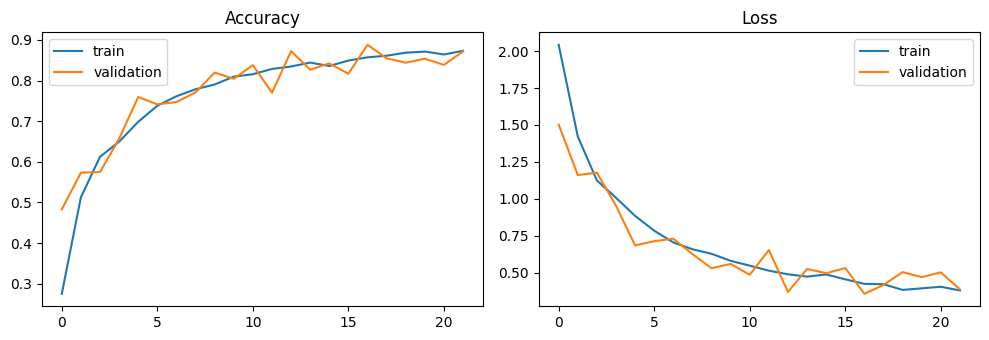

In [32]:
# Learning curves: a growing gap between train and validation means overfitting
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].legend()
plt.tight_layout(); plt.show()

### 3.3 Evaluate on the unseen test set
Accuracy can hide poor results on rare diseases, so we also look at precision (when it says a disease, how often it is right), recall (of all real cases, how many it finds) and F1 (a balance of the two), per class.

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.959     0.878     0.917       319
                        Tomato_Early_blight      0.737     0.880     0.802       150
                         Tomato_Late_blight      0.910     0.856     0.882       285
                           Tomato_Leaf_Mold      0.898     0.923     0.910       143
                  Tomato_Septoria_leaf_spot      0.966     0.846     0.902       266
Tomato_Spider_mites_Two_spotted_spider_mite      0.775     0.797     0.786       251
                        Tomato__Target_Spot      0.796     0.796     0.796       211
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.959     0.927     0.943       481
                Tomato__Tomato_mosaic_virus      0.789     1.000     0.882        56
                             Tomato_healthy      0.859     0.996     0.922       238

                       

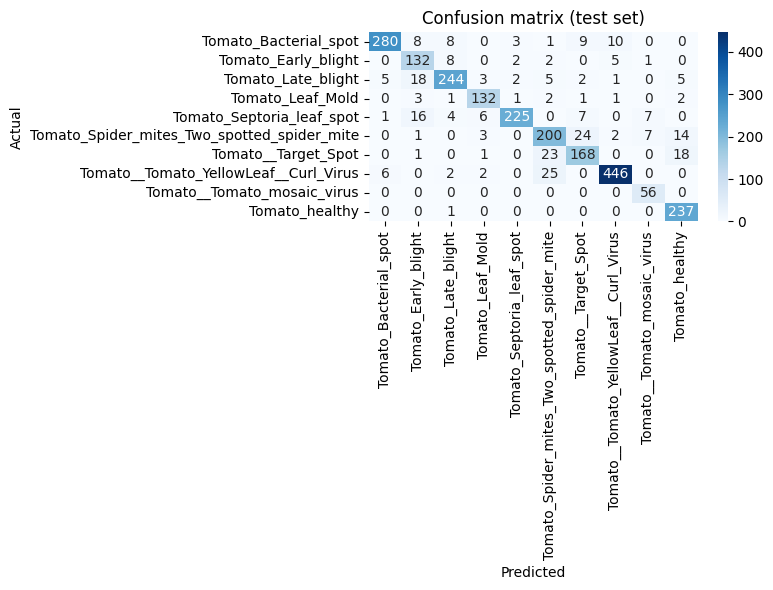

In [33]:
y_true = test_df.label.map(class_to_idx).values
y_pred = np.argmax(model.predict(test_ds), axis=1)

short = [c.replace("Tomato___", "") for c in classes]
print(classification_report(y_true, y_pred, target_names=short, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short, yticklabels=short)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

### 3.4 Stratified k-fold cross-validation
**Idea first:** One train/validation split could be lucky or unlucky. Cross-validation repeats the experiment k times, each time using a different fifth of the data for validation, and averages the scores. A small spread across folds shows the result is stable and not a fluke. Fewer epochs are used per fold to keep run time reasonable.

In [34]:
trainval_df = pd.concat([train_df, val_df]).reset_index(drop=True)   # test set stays untouched
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(trainval_df, trainval_df.label), start=1):
    tr, va = trainval_df.iloc[tr_idx], trainval_df.iloc[va_idx]
    m = compile_model(build_cnn(n_classes))
    m.fit(make_ds(tr, True), epochs=10, class_weight=get_class_weight(tr), verbose=0)
    va_ds = make_ds(va)
    pred = np.argmax(m.predict(va_ds, verbose=0), axis=1)
    true = va.label.map(class_to_idx).values
    acc = (pred == true).mean()
    f1 = f1_score(true, pred, average="macro")
    cv_results.append({"fold": fold, "accuracy": acc, "macro_f1": f1})
    print(f"Fold {fold}: accuracy={acc:.3f}, macro F1={f1:.3f}")

cv_df = pd.DataFrame(cv_results)
print("\nMean accuracy: %.3f (+/- %.3f)" % (cv_df.accuracy.mean(), cv_df.accuracy.std()))
print("Mean macro F1: %.3f (+/- %.3f)" % (cv_df.macro_f1.mean(), cv_df.macro_f1.std()))

Fold 1: accuracy=0.722, macro F1=0.705
Fold 2: accuracy=0.775, macro F1=0.762
Fold 3: accuracy=0.812, macro F1=0.791
Fold 4: accuracy=0.614, macro F1=0.594
Fold 5: accuracy=0.865, macro F1=0.848

Mean accuracy: 0.758 (+/- 0.096)
Mean macro F1: 0.740 (+/- 0.096)


## 4. Further validation of the base model (Question 4)

**Idea first:** If a single model scores well, it could be because the task is easy or because the model is good. Training other models on the same data, split and metrics shows which. If different approaches reach similar results, we can trust the result more. If the CNN beats a simple baseline by a clear margin, the extra complexity is justified.


| Model | Why it is included |
|---|---|
| Base CNN (this notebook) | Built from scratch; our reference |
| MobileNetV2 (transfer learning) | Pretrained on ImageNet and designed to run on phones; likely to be the model deployed in the app |
| Second pretrained model (ResNet50 or EfficientNetB0) | Checks that the result is not specific to one architecture |
| Random Forest or SVM on extracted features | Classical baseline showing what deep learning adds |


Starter for the transfer-learning model:

In [36]:
comparison.loc[0, "test_accuracy"] = round((y_true == y_pred).mean(), 3)
comparison.loc[0, "macro_f1"] = round(f1_score(y_true, y_pred, average="macro"), 3)
comparison

,model,test_accuracy,macro_f1,cv_mean_accuracy
0,Base CNN,0.883,0.874,None
1,MobileNetV2,None,None,None
2,ResNet50 / EfficientNetB0,None,None,None
3,Random Forest / SVM,None,None,None


In [35]:
def build_mobilenet(n_classes):
    base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False                                 # reuse learned features first
    return models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.Rescaling(1.0 / 127.5, offset=-1),          # MobileNetV2 expects -1 to 1
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ])

# To run later:
# mobilenet = compile_model(build_mobilenet(n_classes))
# mobilenet.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[early_stop], class_weight=get_class_weight(train_df))

# Results table to complete as each model is trained
comparison = pd.DataFrame({
    "model": ["Base CNN", "MobileNetV2", "ResNet50 / EfficientNetB0", "Random Forest / SVM"],
    "test_accuracy": [None] * 4,
    "macro_f1": [None] * 4,
    "cv_mean_accuracy": [None] * 4,
})
comparison

,model,test_accuracy,macro_f1,cv_mean_accuracy
0,Base CNN,None,None,None
1,MobileNetV2,None,None,None
2,ResNet50 / EfficientNetB0,None,None,None
3,Random Forest / SVM,None,None,None
